# TRANSFER LEARNING

In [1]:
from __future__ import print_function, division
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

### Загрузка данных

Для загрузки данных используются пакеты torchvision и torch.utils.data.

Данные берутся из подготовленного набора, сформированного в notebook 7.1.


In [2]:
# Увеличение количества данных и их нормализация
# Нормализация для проверки
data_transforms = {
     'train': transforms.Compose([
         transforms.RandomResizedCrop(224),
         transforms.RandomHorizontalFlip(),
         transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ]),
     'val': transforms.Compose([
         transforms.Resize(256),
         transforms.CenterCrop(224),
         transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ]),
     'test': transforms.Compose([
         transforms.Resize(256),
         transforms.CenterCrop(224),
         transforms.ToTensor(),
         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
     ]),
}

# prepared-датасет из notebook 7.1.
data_dir = os.path.join(os.getcwd(), '.data', 'wonders-of-world-prepared')

# ImageFolder считывает изображения из папок train / val / test.
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val', 'test']}

# DataLoader собирает изображения в батчи для обучения и оценки.
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=True, num_workers=4)
               for x in ['train', 'val', 'test']}

# Размеры выборок нужны для вычисления средней ошибки и accuracy.
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}

# Список названий классов берется из train-папки.
class_names = image_datasets['train'].classes

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda:0")
else:
    device = torch.device("cpu")


### Визуализация нескольких образцов

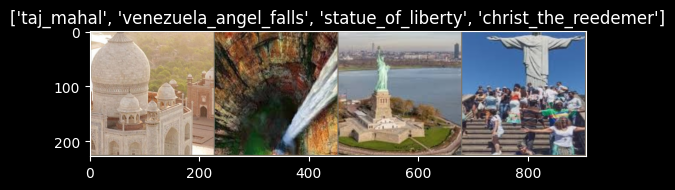

In [3]:
def imshow(inp, title=None):
    """Imshow для тензора."""
    # После make_grid тензор имеет формат (C, H, W), а matplotlib ожидает (H, W, C).
    inp = inp.numpy().transpose((1, 2, 0))
    # Это средние значения каналов, использованные при нормализации ImageNet.
    mean = np.array([0.485, 0.456, 0.406])
    # Это стандартные отклонения каналов, использованные при нормализации ImageNet.
    std = np.array([0.229, 0.224, 0.225])
    # Обратное преобразование нормализации, чтобы изображение можно было показать.
    inp = std * inp + mean
    # Ограничение значений диапазоном [0, 1] для корректного отображения.
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

# Получение одного батча обучающего набора.
inputs, classes = next(iter(dataloaders['train']))

# make_grid объединяет несколько изображений из батча в одну общую сетку.
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])


### Обучение модели

Напишем общую функцию для обучения модели. Здесь можно настроить:
1. Планирование скорости обучения
2. Сохранение лучшей модели

Параметр scheduler - это объект планировщика LR из torch.optim.lr_scheduler.

In [4]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
        
    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)
        
        # Для каждой эпохи прописываем этап обучения и волидации
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train() # Уставновка модели в режим обучения
            else:
                model.eval() # Set ставновка модели в режим оценки
             
            running_loss = 0.0
            running_corrects = 0
                
            # Перебор данных
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # Обнуление градиентов параметров
                optimizer.zero_grad()

                # Отслеживание истории батча при обучении
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    
                    # Оптимизация на этапе обучения
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                
                # Статистикаs
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()
                
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.item() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(
                phase, epoch_loss, epoch_acc))
            
            # Копирование модели
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
    time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))
    # Загрузка лучших весов модели
    model.load_state_dict(best_model_wts)
    return model

### Визуализация прогнозов модели

Общая функция для отображения прогнозов для нескольких изображений.

In [5]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title('predicted: {}'.format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])
                
                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

### Тонкая настройка сверточной сети

Загрузка предварительно обученной модели и сброс крайнего полно-связанного слоя.

In [6]:
# Загружается ResNet18 с весами, предварительно обученными на ImageNet.
model_ft = models.resnet18(pretrained=True)

# in_features — количество входов в последний полносвязный слой.
num_ftrs = model_ft.fc.in_features

# Последний слой заменяется, чтобы число выходов совпадало с количеством классов.
model_ft.fc = nn.Linear(num_ftrs, len(class_names))

# Модель переносится на выбранное устройство.
model_ft = model_ft.to(device)

# CrossEntropyLoss используется для многоклассовой классификации.
criterion = nn.CrossEntropyLoss()

# Здесь обучаются все параметры модели, а не только последний слой.
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# StepLR уменьшает скорость обучения в 10 раз каждые 7 эпох.
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)


/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/mikhail/Developer/SUSU.PE/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


### Тренировка и оценка

In [7]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 1.1888 Acc: 0.6337
val Loss: 0.3330 Acc: 0.9035

Epoch 1/24
----------
train Loss: 0.7795 Acc: 0.7632
val Loss: 0.2494 Acc: 0.9281

Epoch 2/24
----------
train Loss: 0.6558 Acc: 0.8008
val Loss: 0.2107 Acc: 0.9509

Epoch 3/24
----------
train Loss: 0.6173 Acc: 0.8179
val Loss: 0.1705 Acc: 0.9421

Epoch 4/24
----------
train Loss: 0.6430 Acc: 0.8057
val Loss: 0.1983 Acc: 0.9491

Epoch 5/24
----------
train Loss: 0.5061 Acc: 0.8511
val Loss: 0.1937 Acc: 0.9368

Epoch 6/24
----------
train Loss: 0.5057 Acc: 0.8492
val Loss: 0.1507 Acc: 0.9544

Epoch 7/24
----------
train Loss: 0.4208 Acc: 0.8686
val Loss: 0.1283 Acc: 0.9684

Epoch 8/24
----------
train Loss: 0.3722 Acc: 0.8872
val Loss: 0.1143 Acc: 0.9667

Epoch 9/24
----------
train Loss: 0.3314 Acc: 0.8980
val Loss: 0.1058 Acc: 0.9684

Epoch 10/24
----------
train Loss: 0.3240 Acc: 0.8987
val Loss: 0.1188 Acc: 0.9684

Epoch 11/24
----------
train Loss: 0.3152 Acc: 0.9036
val Loss: 0.1047 Acc: 0.9702

Ep

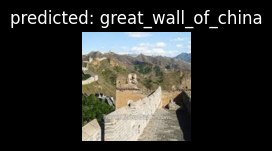

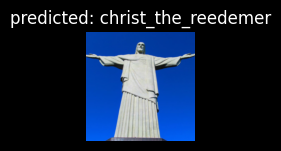

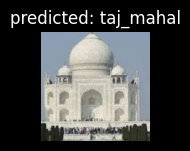

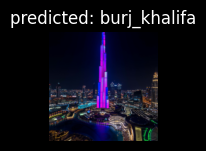

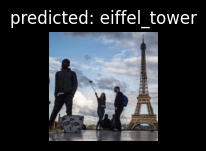

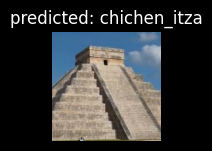

In [8]:
visualize_model(model_ft)

### ConvNet как средство извлечения фиксированных функций

Далее необходимо заморозить всю сеть, кроме последнего слоя. Необходимо установить замораживание параметров,
чтобы градиенты не вычислялись в .requires_grad = Falsebackward().

Подробнее об этом можно прочитать в документации здесь - https://pytorch.org/docs/master/notes/autograd.html

In [9]:
# Загружается та же ResNet18 с предобученными весами.
model_conv = torchvision.models.resnet18(pretrained=True)

# Все параметры сверточной базы замораживаются.
for param in model_conv.parameters():
    param.requires_grad = False

# Определяется размер входа в последний полносвязный слой.
num_ftrs = model_conv.fc.in_features

# Последний слой заменяется новым классификатором под наш набор классов.
model_conv.fc = nn.Linear(num_ftrs, len(class_names))

# Модель переносится на выбранное устройство.
model_conv = model_conv.to(device)

# Функция потерь для многоклассовой классификации.
criterion = nn.CrossEntropyLoss()

# Оптимизируются только параметры последнего слоя.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# StepLR уменьшает скорость обучения в 10 раз каждые 7 эпох.
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)


### Тренировка и оценка

Здесь вы можете увидеть, что время сократилось. Это происходит потому, что градиенты больше не нужно
вычислять.


In [10]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 1.4545 Acc: 0.5339
val Loss: 0.4037 Acc: 0.8825

Epoch 1/24
----------
train Loss: 0.9531 Acc: 0.7066
val Loss: 0.3829 Acc: 0.8877

Epoch 2/24
----------
train Loss: 0.8458 Acc: 0.7543
val Loss: 0.3007 Acc: 0.9105

Epoch 3/24
----------
train Loss: 0.8428 Acc: 0.7480
val Loss: 0.2900 Acc: 0.9193

Epoch 4/24
----------
train Loss: 0.8191 Acc: 0.7491
val Loss: 0.2993 Acc: 0.9105

Epoch 5/24
----------
train Loss: 0.8180 Acc: 0.7539
val Loss: 0.3557 Acc: 0.8947

Epoch 6/24
----------
train Loss: 0.7784 Acc: 0.7718
val Loss: 0.2919 Acc: 0.9070

Epoch 7/24
----------
train Loss: 0.7222 Acc: 0.7852
val Loss: 0.2692 Acc: 0.9140

Epoch 8/24
----------
train Loss: 0.7148 Acc: 0.7759
val Loss: 0.2677 Acc: 0.9211

Epoch 9/24
----------
train Loss: 0.6891 Acc: 0.7926
val Loss: 0.2470 Acc: 0.9193

Epoch 10/24
----------
train Loss: 0.6993 Acc: 0.7829
val Loss: 0.2597 Acc: 0.9211

Epoch 11/24
----------
train Loss: 0.6817 Acc: 0.7975
val Loss: 0.2452 Acc: 0.9228

Ep

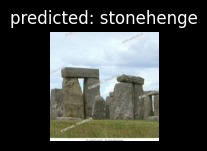

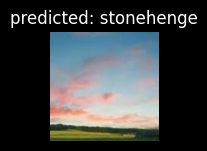

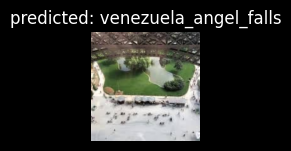

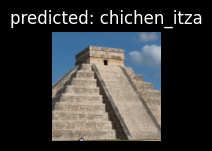

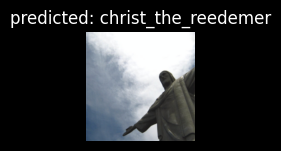

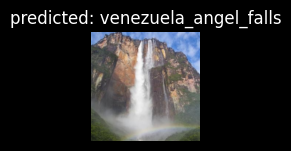

In [11]:
visualize_model(model_conv)
plt.ioff()
plt.show()

### Оценка на тестовой выборке


In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

def evaluate_model(model, criterion):
    # Сохраняется исходный режим модели, чтобы потом вернуть его обратно.
    was_training = model.training
    # Переключение в режим оценки отключает поведение, зависящее от обучения.
    model.eval()

    # Накопление суммы ошибки по всем батчам.
    running_loss = 0.0
    # Накопление количества правильных ответов.
    running_corrects = 0
    # Списки понадобятся для матрицы ошибок.
    true_labels = []
    predicted_labels = []

    # На этапе оценки градиенты не требуются.
    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            # Батч переносится на выбранное устройство.
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Прямой проход модели.
            outputs = model(inputs)
            # По максимальному выходу выбирается предсказанный класс.
            _, preds = torch.max(outputs, 1)
            # Вычисляется ошибка на батче.
            loss = criterion(outputs, labels)

            # Накапливается сумма ошибки с учетом размера батча.
            running_loss += loss.item() * inputs.size(0)
            # Накапливается число правильных классификаций.
            running_corrects += torch.sum(preds == labels.data)
            # Истинные и предсказанные классы сохраняются для матрицы ошибок.
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(preds.cpu().numpy())

    # Средняя ошибка по всей тестовой выборке.
    test_loss = running_loss / dataset_sizes['test']
    # Accuracy считается как доля правильных ответов.
    test_acc = running_corrects.item() / dataset_sizes['test']

    print('Test Loss: {:.4f} Acc: {:.4f}'.format(test_loss, test_acc))
    # Возврат исходного режима модели.
    model.train(mode=was_training)
    return true_labels, predicted_labels


def plot_confusion_matrix(true_labels, predicted_labels, title):
    # По предсказаниям и истинным меткам строится матрица ошибок.
    cm = confusion_matrix(true_labels, predicted_labels)
    # Создается фигура для отображения матрицы.
    fig, ax = plt.subplots(figsize=(8, 8))
    # ConfusionMatrixDisplay рисует матрицу с подписями классов.
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    display.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


Test Loss: 0.0541 Acc: 0.9831


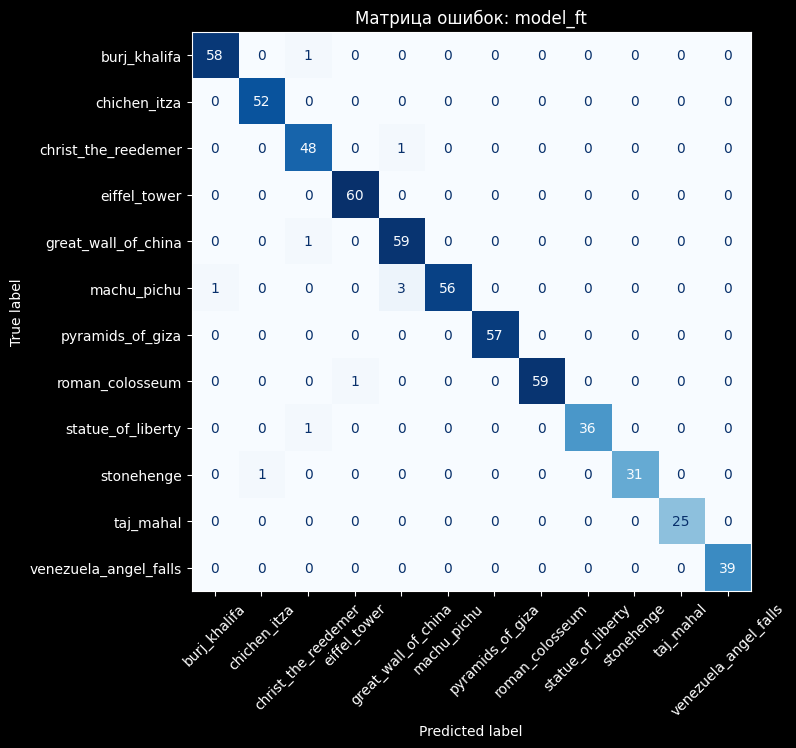

In [13]:
true_labels, predicted_labels = evaluate_model(model_ft, criterion)
plot_confusion_matrix(true_labels, predicted_labels, 'Матрица ошибок: model_ft')


Test Loss: 0.1840 Acc: 0.9424


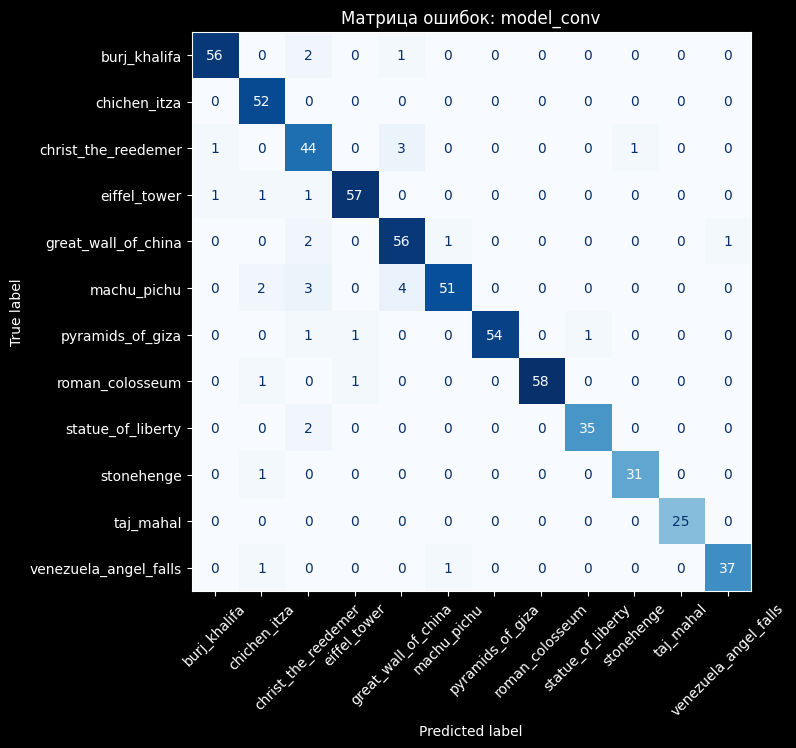

In [14]:
true_labels, predicted_labels = evaluate_model(model_conv, criterion)
plot_confusion_matrix(true_labels, predicted_labels, 'Матрица ошибок: model_conv')
